In [48]:
import numpy as np 
import pandas as pd 
import seaborn as sns 
from scipy import stats
import matplotlib.pyplot as plt
from statsmodels.stats.proportion import proportion_effectsize
from statsmodels.stats.proportion import proportions_ztest 
from statsmodels.stats.multitest import multipletests




In [49]:
# Använd slump-seed för reproducerbarhet
np.random.seed(42) 

# Läs in dataset
df = pd.read_csv("data/health_study_dataset.csv")

# Kontrollera om det finns saknade värden, dubbletter eller ogiltiga värden
nan_count = df.disease.isna().sum() 
duplicated_count = df.duplicated().sum() 

# Skapa en mask för att hitta värden som varken är 0 eller 1 i disease kolumnen 
invalid_mask = ~df.disease.isin([0, 1]) & ~df.disease.isna() 
invalid_count = invalid_mask.sum() 

print("--- Data check ---") 
print(f"Missing values: {nan_count}") 
print(f"Duplicate rows: {duplicated_count}") 
print(f"Invalid values): {invalid_count}") 

# Rensa bort tomma värden & dubbletter med .dropna (NaN)
rows = len(df) 
df = df.dropna().drop_duplicates()
cleaned_rows = len(df) 

print(f"Rows before cleaning: {rows}") 
print(f"Rows after cleaning: {cleaned_rows}") 

# Justera radnumren från 0,1,2….
df = df.reset_index(drop=True)

# Verifiera att allt fungerar 
df.head()
df.info()

--- Data check ---
Missing values: 0
Duplicate rows: 0
Invalid values): 0
Rows before cleaning: 800
Rows after cleaning: 800
<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           800 non-null    int64  
 1   age          800 non-null    int64  
 2   sex          800 non-null    str    
 3   height       800 non-null    float64
 4   weight       800 non-null    float64
 5   systolic_bp  800 non-null    float64
 6   cholesterol  800 non-null    float64
 7   smoker       800 non-null    str    
 8   disease      800 non-null    int64  
dtypes: float64(4), int64(3), str(2)
memory usage: 56.4 KB


## BESKRIVANDE ANALYS

- Räkna ut medel, median, min och max
- Skapa 3 olika grafer

In [50]:
# Använd .agg()

# Välj ut variablerna 
columns = ["age", "weight", "height", "systolic_bp", "cholesterol"]

# Räkna ut medelvärde, median, min & max 
summary = df[columns].agg(["mean", "median", "min", "max"]) 
display(summary)


,age,weight,height,systolic_bp,cholesterol
mean,49.42625,73.413,171.84925,149.178625,4.92915
median,50.00000,73.200,171.35000,149.400000,4.97000
min,18.00000,33.700,144.40000,106.800000,2.50000
max,90.00000,114.400,200.40000,185.900000,7.88000


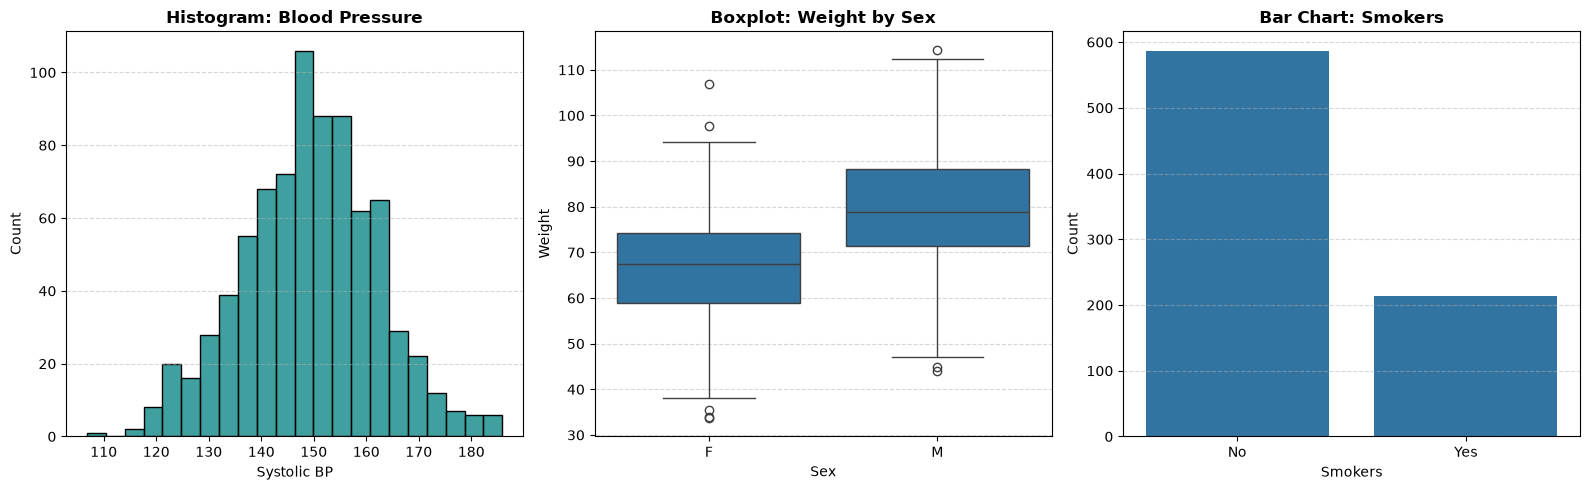

In [61]:
# 3 grafer brevid varandra
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(16, 5))

# Graf 1 - Histogram, blodtryck
sns.histplot(df["systolic_bp"], color="teal", ax=ax1)
ax1.set_title("Histogram: Blood Pressure", fontsize=12, fontweight="bold")
ax1.set_xlabel("Systolic BP")
ax1.set_ylabel("Count")
ax1.grid(axis="y", linestyle="--", alpha=0.5)

# Graf 2 - Låddiagram, vikt per kön
sns.boxplot(x="sex", y="weight", data=df, ax=ax2)
ax2.set_title("Boxplot: Weight by Sex", fontsize=12, fontweight="bold")
ax2.set_xlabel("Sex")
ax2.set_ylabel("Weight")
ax2.grid(axis="y", linestyle="--", alpha=0.5)


# Graf 3 - Stapeldiagram, rökare
sns.countplot(x="smoker", data=df, ax=ax3)
ax3.set_title("Bar Chart: Smokers", fontsize=12, fontweight="bold")
ax3.set_xlabel("Smokers")
ax3.set_ylabel("Count")
ax3.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()



## SIMULERING

- Beräkna andelen personer i datasetet som har sjukdomen.
- Simulera 1000 slumpade personer med samma sannolikhet för sjukdom.
- Jämför den simulerade andelen med den verkliga andelen i datasetet.


In [52]:
# Använd numpy.random + seed

# Kolla på den totala populationen i datasetet
total_population = len(df) 
print("---- Disease rate ----")
print(f"Total population: {total_population}") 

# Beräkna hur många av dem som har sjukdomen
total_with_disease = df["disease"].sum() 
print(f"Individuals with the disease: {total_with_disease}") 

# Beräkna andelen som har sjukdomen genom medelvärdet
p_real = df["disease"].mean()
print(f"Disease rate: {p_real * 100:.2f} %")



---- Disease rate ----
Total population: 800
Individuals with the disease: 47
Disease rate: 5.88 %


In [53]:
# Simulera 1000 slumpade personer
n_simulated = 1000 
simulated_disease = np.random.binomial(n=1, p=p_real, size=n_simulated) 

# Beräkna andelen i den simulerade gruppen
p_simulated = simulated_disease.mean()
total_simulated_disease = simulated_disease.sum()

print("---- Simulated disease rate ----")
print( f"Number of individuals with disease in simulation:" f" {total_simulated_disease}" )
print( f"Simulated disease rate: {p_simulated * 100:.2f} %" )



---- Simulated disease rate ----
Number of individuals with disease in simulation: 56
Simulated disease rate: 5.60 %


In [54]:
# Jämför den simulerade andelen genom att beräkna skillnaden
difference = abs(p_simulated - p_real) 

print("---- Difference ----")
print(f"True disease rate: {p_real * 100:.2f} %") 
print(f"Simulated disease rate: {p_simulated * 100:.2f} %") 
print(f"Absolute difference: {difference * 100:.2f} %")


---- Difference ----
True disease rate: 5.88 %
Simulated disease rate: 5.60 %
Absolute difference: 0.27 %


## Konfidensintervall

- Beräkna konfidensintervallet med två olika metoder och jämför resultaten.
- Gör en simulering för att undersöka hur säkert ditt hypotes­test är
- Motivera dina metodval i markdown


In [55]:
# METOD 1: T-fördelning

# Ta fram medelvärdet för bp från tidigare summary tabell
mean_val = summary.loc["mean", "systolic_bp"] 

# Ta fram antalet personer i datasetet
n = len(df)

# Ta fram stickprovsstandardavvikelse för blodtrycket 
sd = df["systolic_bp"].std(ddof=1)

# Beräkna standardfelet SE
standard_error = sd / np.sqrt(n) 

# Beräkna 95% konfidensintervall 
ci_t = stats.t.interval(0.95, df=n - 1, loc=mean_val, scale=standard_error) 

print("--- METOD 1 ---")
print(f"Mean Blood Pressure: {mean_val:.2f}")
print(f"95% Confidence Interval: ({ci_t[0]:.2f}, {ci_t[1]:.2f})")


--- METOD 1 ---
Mean Blood Pressure: 149.18
95% Confidence Interval: (148.29, 150.07)


In [56]:
# METOD 2: Bootstrap-metoden

# Skapa en tom lista 
np.random.seed(42)
n_bootstraps = 1000
boot_mean = [] 

for _ in range(n_bootstraps): 
    sample = df["systolic_bp"].sample(n=n, replace=True) 
    boot_mean.append(sample.mean())

ci_boot = np.percentile(boot_mean, [2.5, 97.5]) 

print("--- METOD 2 ---")
print(f"Mean Blood Pressure: {mean_val:.2f}")
print(f"95% Confidence Interval: ({ci_boot[0]:.2f}, {ci_boot[1]:.2f})")


--- METOD 2 ---
Mean Blood Pressure: 149.18
95% Confidence Interval: (148.31, 150.10)


## Hypotesprövning

- Testa hypotesen: ”Rökare har högre medel-blodtryck än icke-rökare.”
- Använd en av metoderna vi gått igenom
- Förklara kort resultatet i en markdown-ruta

In [57]:
# Ta fram antalet rökare och icke-rökare i datasetet
smokers = df[df["smoker"] == "Yes"]["systolic_bp"]
print(f"Smokers: {len(smokers)}")

non_smokers = df[df["smoker"] == "No"]["systolic_bp"]
print(f"Non-smokers: {len(non_smokers)}")

Smokers: 213
Non-smokers: 587


In [58]:
# Räkna ut blodtrycks-medelvärdet för antalet rökare

mean_smokers = smokers.mean() 
print(f"Mean bp for smokers: {mean_smokers:.2f}") 

mean_non_smokers = non_smokers.mean() 
print(f"Mean bp for non-smokers: {mean_non_smokers:.2f}") 


Mean bp for smokers: 149.52
Mean bp for non-smokers: 149.05


In [59]:
# Gör ett welchs test 
t_stat, p_value = stats.ttest_ind(smokers, non_smokers, equal_var=False) 

print(f"T-stat: {t_stat:.2f}") 
print(f"P-value: {p_value:.5f}") 

# Gör en kontroll av signifikans vid alpha 0,05%
alpha = 0.05 
if p_value < alpha: 
    print("Resultat: Signifikant skillnad finns. Vi förkastar nollhypotesen. ")

else: 
    print("Resultat: Vi kan inte förkasta nollhypotesen.")


T-stat: 0.45
P-value: 0.65273
Resultat: Vi kan inte förkasta nollhypotesen.


- Skillnaden i blodtryck medelvärde mellan grupperna är så liten att den troligtvis beror på slumpen. 
- P-värdet slutade på 0.65237 vilket är över vår signifikansnivå 0.05. Därför kan vi inte förkasta nollhypotesen. 

In [60]:
# Simulering av hypotestest
# Undersök hur ofta testet upptäcker skillnaden (Power-simulering)


n_simulations = 1000
significant_count = 0
np.random.seed(42)

# Dra stickprov från respektive grupp
for _ in range(n_simulations):
    sim_smokers = smokers.sample(n=1000, replace=True)
    sim_non_smokers = non_smokers.sample(n=1000, replace=True)
    
    _, p_val = stats.ttest_ind(sim_smokers, sim_non_smokers, equal_var=False)
    if p_val < 0.05:
        significant_count += 1

power_estimate = significant_count / n_simulations
print(f"Estimerad statistisk power vid n=100 per grupp: {power_estimate * 100:.2f}%")



Estimerad statistisk power vid n=100 per grupp: 15.70%



# Jämförelse av konfidensintervall
För att beräkna konfidensintervallet valde jag att använda två olika metoder, en teoretisk metod och en simuleringsmetod.
- T-fördelningen bygger på en fast formel och är snabb att räkna ut. Den förutsätter att urvalet är representativt och att stickprovsfördelningen är ungefär normal. Eftersom standardavvikelsen var okänd och uppskattas från stickprovet har jag (enligt kursmaterialet) använt ett t-intervall i stället för z-värdet 1,96.
- Bootstrap-metoden är en datadriven simuleringsmetod som skapar nya stickprov direkt ur vår egen data genom återläggning, utan att kräva samma strikta formler (även om den förutsätter att originalstickprovet ger en rimlig bild av populationen, vilket kursmaterialet säger).

Eftersom båda metoderna gav nästan exakt samma svar, känner jag mig säker på att siffrorna stämmer och att skattningen är stabil.

# Welch's t-test
Jag valde att använda ett Welch's t-test eftersom rökare och icke-rökare inte har exakt samma spridning på sina värden i datasetet. Welch-testet det säkraste valet när grupper har olika varianser, eftersom det inte förutsätter att spridningen är identisk. Det gör att vi kan lita mer på resultatet i det här fallet.

# Statistisk styrka
Simuleringen visade en power på 15,70 % vid ett stickprov på n=1000. Att styrkan är relativt låg beror helt på att det inte finns någon verklig eller signifikant skillnad i blodtryck mellan rökare och icke-rökare i grunddatan (vilket även vårt höga p-värde visade). En låg power betyder att testet har en låg sannolikhet att upptäcka en skillnad, vilket även vår data visar. 
